In [3]:
import SimpleITK as sitk
import numpy as np
import os
import matplotlib.pyplot as plt
from glob import glob


Paths Setup

In [19]:
input_dir = "../Desktop/project - Copy/data/subset"  # adjust as needed
output_dir = "../Desktop/project - Copy/preprocessed/resampled"
os.makedirs(output_dir, exist_ok=True)

sample_scan = glob(f"{input_dir}/*.mhd")[0]  # test on one scan first


Resample Function

In [21]:
def resample_scan(image, new_spacing=[1, 1, 1]):
    original_spacing = image.GetSpacing()
    original_size = image.GetSize()

    # Compute new size
    new_size = [
        int(round(osz * ospc / nspc))
        for osz, ospc, nspc in zip(original_size, original_spacing, new_spacing)
    ]

    resample = sitk.ResampleImageFilter()
    resample.SetInterpolator(sitk.sitkLinear)
    resample.SetOutputSpacing(new_spacing)
    resample.SetSize(new_size)
    resample.SetOutputOrigin(image.GetOrigin())
    resample.SetOutputDirection(image.GetDirection())
    resampled_image = resample.Execute(image)

    return resampled_image


📊 Visual Comparison Function



In [23]:
def show_middle_slices(original, resampled):
    original_np = sitk.GetArrayFromImage(original)
    resampled_np = sitk.GetArrayFromImage(resampled)

    fig, axs = plt.subplots(1, 2, figsize=(12, 6))

    axs[0].imshow(original_np[original_np.shape[0] // 2], cmap='gray')
    axs[0].set_title("Original Middle Slice")

    axs[1].imshow(resampled_np[resampled_np.shape[0] // 2], cmap='gray')
    axs[1].set_title("Resampled Middle Slice")

    plt.tight_layout()
    plt.show()


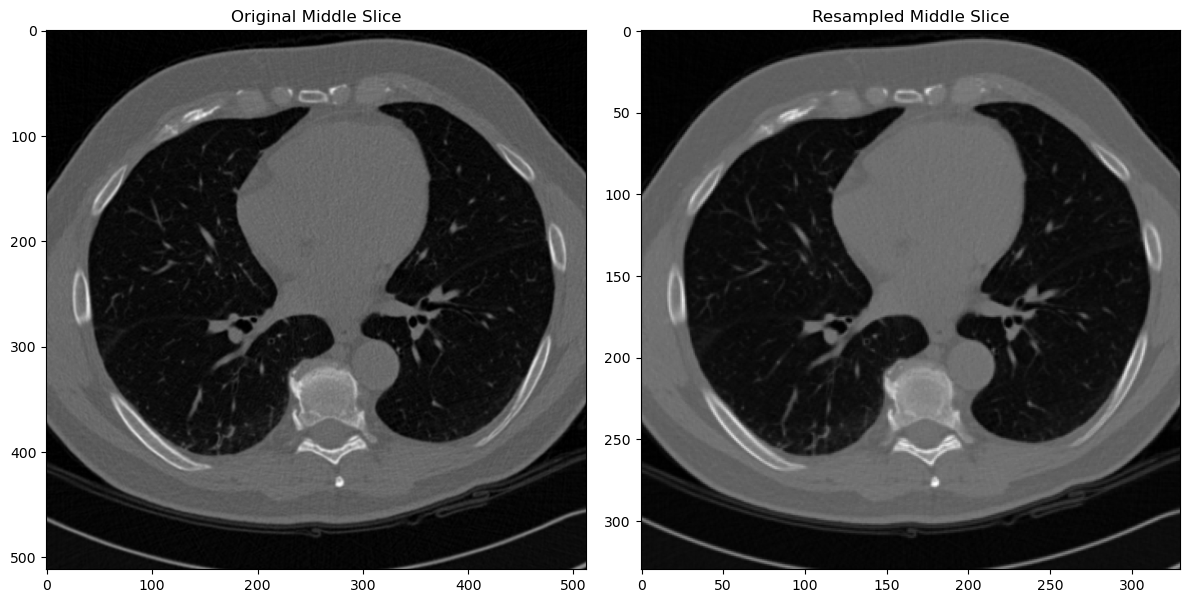

In [25]:
scan = sitk.ReadImage(sample_scan)
resampled = resample_scan(scan, new_spacing=[1, 1, 1])
show_middle_slices(scan, resampled)



In [27]:
print("Original spacing:", scan.GetSpacing())
print("Resampled spacing:", resampled.GetSpacing())


Original spacing: (0.64453125, 0.64453125, 1.7999999523162842)
Resampled spacing: (1.0, 1.0, 1.0)


In [31]:
all_scans = glob(f"{input_dir}/*.mhd")

for scan_path in all_scans:
    print(f"Resampling: {scan_path}")
    scan = sitk.ReadImage(scan_path)
    resampled = resample_scan(scan, new_spacing=[1,1,1])

    # Save with new filename
    uid = os.path.basename(scan_path).replace(".mhd", "_resampled.mhd")
    sitk.WriteImage(resampled, os.path.join(output_dir, uid))


Resampling: ../Desktop/project - Copy/data/subset\1.3.6.1.4.1.14519.5.2.1.6279.6001.100225287222365663678666836860.mhd
Resampling: ../Desktop/project - Copy/data/subset\1.3.6.1.4.1.14519.5.2.1.6279.6001.100332161840553388986847034053.mhd
Resampling: ../Desktop/project - Copy/data/subset\1.3.6.1.4.1.14519.5.2.1.6279.6001.100398138793540579077826395208.mhd
Resampling: ../Desktop/project - Copy/data/subset\1.3.6.1.4.1.14519.5.2.1.6279.6001.100530488926682752765845212286.mhd
Resampling: ../Desktop/project - Copy/data/subset\1.3.6.1.4.1.14519.5.2.1.6279.6001.100620385482151095585000946543.mhd
Resampling: ../Desktop/project - Copy/data/subset\1.3.6.1.4.1.14519.5.2.1.6279.6001.100621383016233746780170740405.mhd
Resampling: ../Desktop/project - Copy/data/subset\1.3.6.1.4.1.14519.5.2.1.6279.6001.100684836163890911914061745866.mhd
Resampling: ../Desktop/project - Copy/data/subset\1.3.6.1.4.1.14519.5.2.1.6279.6001.100953483028192176989979435275.mhd
Resampling: ../Desktop/project - Copy/data/subse

In [35]:
import SimpleITK as sitk
from glob import glob
import os

# Paths
resampled_dir = "../Desktop/project - Copy/preprocessed/resampled"
original_dir =  "../Desktop/project - Copy/data/subset" 

# Step 1: List files
original_scans = glob(f"{original_dir}/*.mhd")
resampled_scans = glob(f"{resampled_dir}/*.mhd")

print(f"Original scans: {len(original_scans)}")
print(f"Resampled scans: {len(resampled_scans)}")

# Step 2: Check if counts match
if len(original_scans) != len(resampled_scans):
    print("⚠️ Warning: Number of resampled scans does not match originals!")
else:
    print("✅ Number of resampled scans matches originals.")

# Step 3: Check spacing
errors = []

for resample_path in resampled_scans:
    image = sitk.ReadImage(resample_path)
    spacing = image.GetSpacing()

    if not (np.allclose(spacing[0], 1.0) and np.allclose(spacing[1], 1.0) and np.allclose(spacing[2], 1.0)):
        errors.append(resample_path)

# Step 4: Report
if not errors:
    print("✅ All resampled scans have correct spacing (1.0, 1.0, 1.0)")
else:
    print(f"⚠️ {len(errors)} scans have incorrect spacing:")
    for e in errors:
        print(" -", os.path.basename(e))


Original scans: 888
Resampled scans: 888
✅ Number of resampled scans matches originals.
✅ All resampled scans have correct spacing (1.0, 1.0, 1.0)
